# ⚖️ Saudi Legal RAG — Retrieving the Governing Article for Arabic Legal Questions
**NLP Course Project** · University of Bisha

**Author:** Nader Al-Shehri

**Task:** retrieve the Saudi-law article that answers an Arabic legal question (RAG) · **Data:** 1,474 articles from 11 laws (laws.boe.gov.sa)

📄 Methodology, insights and findings: **[`docs/REPORT.md`](docs/REPORT.md)**  ·  AI-assistance acknowledgement: see the report.

In [1]:
# --- Setup (Colab: Runtime → Change runtime type → T4 GPU recommended) ---------------
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules


def find_project_root():
    # locate the folder that contains src/ — works on re-runs and with nested unzips
    here = os.getcwd()
    for p in [here, os.path.dirname(here), "/content/saudi-legal-rag", "/content/saudi-legal-rag/saudi-legal-rag"]:
        if os.path.isdir(os.path.join(p, "src")) and os.path.isdir(os.path.join(p, "data")):
            return p
    return None


REPO_URL = "https://github.com/tgfdru/saudi-legal-rag"

ROOT = find_project_root()
if ROOT is None and IN_COLAB:
    zips = [f for f in os.listdir("/content") if f.startswith("saudi-legal-rag") and f.endswith(".zip")]
    if zips:                                                   # option 1: zip uploaded in the Files panel
        import zipfile
        zpath = os.path.join("/content", sorted(zips, key=lambda f: os.path.getmtime(os.path.join("/content", f)))[-1])
        if not zipfile.is_zipfile(zpath):
            raise RuntimeError(f"{os.path.basename(zpath)} is incomplete ({os.path.getsize(zpath)/1e6:.1f} MB) — "
                               "wait for the upload to finish, then run this cell again.")
        zipfile.ZipFile(zpath).extractall("/content")
    elif "YOUR-USERNAME" not in REPO_URL:                      # option 2: clone from GitHub
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/saudi-legal-rag"], check=True)
    ROOT = find_project_root()
if ROOT is None:
    raise FileNotFoundError("Project not found: set REPO_URL above, or upload saudi-legal-rag.zip in the Files panel (📁).")
os.chdir(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)            # Colab does not put the working directory on the import path
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("project folder:", ROOT)

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import torch

from src import config, eda, classify
from src.chunker import load_corpus, corpus_dataframe
from src.normalize import normalize, tokenize

HAS_GPU = torch.cuda.is_available()
RUN_DENSE  = True        # bge-m3 (~2.3 GB download; ~2 min on GPU, ~20 min on CPU first time, then cached)
RUN_RERANK = HAS_GPU or os.getenv("RUN_RERANK") == "1"   # cross-encoder: ~1 s per pair on CPU
RESCRAPE   = False       # True = re-collect the corpus live from laws.boe.gov.sa
os.makedirs(config.FIG_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
print(f"GPU: {HAS_GPU} | dense: {RUN_DENSE} | rerank: {RUN_RERANK}")

project folder: /home/claude/saudi-legal-rag


GPU: False | dense: True | rerank: True


## 1. Data collection
**Question:** given an everyday Arabic legal question, can we retrieve the article of Saudi law that answers it?

- **Source:** Bureau of Experts at the Council of Ministers, [laws.boe.gov.sa](https://laws.boe.gov.sa), the official consolidated text
- **Tool:** `src/scraper.py` (`requests` + `BeautifulSoup`), only in-force article text kept
- **Size / date:** 11 laws → **1,474 articles** (one sample = one article), collected November 2026
- **Ethics:** public legislation with no personal data; one request at a time with a 2 s delay; used for this course only
- Set `RESCRAPE = True` to collect again from the source; otherwise the saved raw files are loaded

In [2]:
if RESCRAPE:
    from src import scraper
    scraper.main(["--all"])

chunks = load_corpus(config.RAW_DIR)
df = corpus_dataframe(chunks)
df.to_csv(config.CORPUS_CSV, index=False, encoding="utf-8-sig")      # ← submitted dataset
print(f"{len(df):,} articles from {df.law.nunique()} laws → saved {config.CORPUS_CSV.name}")

meta = (df.groupby(["law_key", "law"]).agg(articles=("id", "size"), issued=("issued", "first"),
        median_words=("n_words", "median")).reset_index().sort_values("articles", ascending=False))
display(meta)

1,474 articles from 11 laws → saved corpus.csv


,law_key,law,articles,issued,median_words
3,muamalat,نظام المعاملات المدنية,721,1444/11/29 هـ,30.0
6,murafaat_sharia,نظام المرافعات الشرعية,242,1435/01/22 هـ,40.5
2,ithbat,نظام الإثبات,129,1443/05/26 هـ,36.0
8,qada,نظام القضاء,85,1428/09/19 هـ,38.0
9,tanfeedh,نظام التنفيذ,65,1447/11/03 هـ,65.0
5,murafaat_diwan,نظام المرافعات أمام ديوان المظالم,63,1435/01/22 هـ,41.0
4,muhamah,نظام المحاماة,55,1422/07/28 هـ,48.0
10,tanfeedh_diwan,نظام التنفيذ أمام ديوان المظالم,37,1443/01/27 هـ,36.0
0,diwan_al_mazalim,نظام ديوان المظالم,26,1428/09/19 هـ,35.0
7,nazaa_reg,اللائحة التنفيذية لنظام نزع ملكية العقارات للمنفعة العامة ووضع اليد المؤقت على العقار,26,1437/02/11 هـ,121.5


> 💡 **Insight.** 11 laws, 1,474 articles. The Civil Transactions Law alone has 721 articles (49%), so the data is strongly imbalanced, which shapes every evaluation choice below.

## 2. Dataset description
Sample rows and basic statistics

In [3]:
display(df[["id", "law", "chapter", "article", "text", "n_words"]].sample(5, random_state=1))
print(f"Total words: {df.n_words.sum():,} | median article: {df.n_words.median():.0f} words | "
      f"shortest: {df.n_words.min()} | longest: {df.n_words.max()}")
print(f"Articles with a chapter heading: {(df.chapter != '').mean():.0%}")

,id,law,chapter,article,text,n_words
1126,murafaat_sharia#108,نظام المرافعات الشرعية,,المادة الثامنة بعد المائة,إقرار الخصم - عند الاستجواب أو دون استجوابه - حجة قاصـرة عليه، ويجب أن يكون الإقرار حاصلًا أمام القضاء أثناء السير ف...,27
390,muamalat#211,نظام المعاملات المدنية,,المادة الحادية عشرة بعد المائتين,يكون الالتزام بدليًّا إذا لم يشمل محله إلا شيئًا واحدًا، مع حق المدين أن يؤدي بدلًا منه شيئًا آخر.\nالأصل لا البدل ه...,30
824,muamalat#645,نظام المعاملات المدنية,,المادة الخامسة والأربعون بعد الستمائة,يملك الوارث بالإرث نصيبه من الأموال المملوكة للمورث، وفقًا للنصوص النظامية الخاصة به.,13
341,muamalat#162,نظام المعاملات المدنية,,المادة الثانية والستون بعد المائة,إذا لم يستوف الالتزام الشروط النظامية لتنفيذه جبرًا يبقى قائمًا في ذمة المدين ديانةً، فإذا وفاه مختارًا كان وفاؤه صح...,27
1213,murafaat_sharia#195,نظام المرافعات الشرعية,,المادة الخامسة والتسعون بعد المائة,1- يحصل الاعتراض بطلب النقض، بمذكرة تودع لدى إدارة محكمة الاستئناف التي أصدرت الحكم أو أيدته. ويجب أن تشتمل مذكرة ال...,83


Total words: 70,178 | median article: 35 words | shortest: 5 | longest: 1047
Articles with a chapter heading: 8%


> 💡 **Insight.** Articles are short (median ≈ 35 words) but written in formal legal drafting, while users ask in everyday Arabic. This vocabulary gap is the core difficulty of the task.

## 3. Preprocessing
The **same** normalizer is applied to articles and to questions, otherwise `اذا` in a question never matches `إذا` in the law.

| Step | Why |
|---|---|
| Arabic-Indic digits → ASCII | `١٥` and `15` are the same number |
| Remove diacritics and tatweel | the law text is partly vocalized, user questions are not |
| أ/إ/آ → ا, ى → ي, ة → ه | the most common spelling variation in typed Arabic |
| Remove punctuation and digits (lexical models only) | numbers inside sentences add noise to word matching |
| Remove stopwords (normalized list) | على / إلى / التي carry no retrieval signal |
| Light stemming (strip ال / وال / بال …) | `الدعوى`, `والدعوى`, `بالدعوى` → one term |

Not applied: lowercasing (Arabic has no case) and root stemming (it merges unrelated legal terms). bge-m3 receives only normalized text, since it has its own sub-word tokenizer.

In [4]:
ex = df.loc[df.text.str.contains("إذا"), "text"].iloc[0][:160]
print("raw        :", ex)
print("normalized :", normalize(ex))
print("tokens     :", tokenize(ex))

raw        : 1 - يكون مقر المحكمة الإدارية العليا مدينة الرياض، وتؤلف من رئيس وعدد كاف من القضاة بدرجة رئيس محكمة استئناف.
2 - يسمى رئيس المحكمة الإدارية العليا بأمر ملكي ، 
normalized : 1 - يكون مقر المحكمه الاداريه العليا مدينه الرياض، وتولف من رييس وعدد كاف من القضاه بدرجه رييس محكمه استيناف. 2 - يسمي رييس المحكمه الاداريه العليا بامر ملكي ،
tokens     : ['مقر', 'محكمه', 'اداريه', 'عليا', 'مدينه', 'رياض', 'وتولف', 'رييس', 'وعدد', 'كاف', 'قضاه', 'بدرجه', 'رييس', 'محكمه', 'استيناف', 'يسمي', 'رييس', 'محكمه', 'اداريه', 'عليا', 'بامر', 'ملكي']


In [5]:
steps = eda.preprocessing_effect(df)
display(steps)

,step,tokens,vocabulary,vocab Δ vs raw
0,1. raw whitespace tokens,70178,12416,+0%
1,2. + remove punctuation,71667,9221,-26%
2,3. + remove diacritics/tatweel,69520,9118,-27%
3,"4. + letter normalization (أإآ→ا, ى→ي, ة→ه)",69520,9041,-27%
4,5. + stopword removal,48567,8940,-28%
5,6. + light stemming (strip ال/وال/بال…),48453,7149,-42%


> 💡 **Insight.** Every step shrinks the vocabulary: from 12,416 to 7,149 word types (−42%). Light stemming alone removes ~1,800 types, mostly the same word with and without `ال`. A smaller vocabulary lets the user's wording and the law's wording meet on the same term, which matters most for TF-IDF and BM25.

In [6]:
dups = df[df.is_dup_text].sort_values("text_clean")[["id", "article", "text"]]
print(f"Exact duplicate article texts: {len(dups)}")
display(dups)
print("Very short articles (< 8 words):", (df.n_words < 8).sum())

Exact duplicate article texts: 2


,id,article,text
1018,murafaat_diwan#063,المادة الثالثة والستون,يعمل بهذا النظام من تاريخ نشره في الجريدة الرسمية.
1260,murafaat_sharia#242,المادة الثانية والأربعون بعد المائتين,يعمل بهذا النظام من تاريخ نشره في الجريدة الرسمية.


Very short articles (< 8 words): 12


> 💡 **Insight.** The only exact duplicates are the boilerplate closing article «يعمل بهذا النظام…» in two laws, and 12 articles have fewer than 8 words. Both are **kept**: each is a separate citable article, and a short article can be the full answer to a question. No empty entries exist.

## 4. Exploratory data analysis
Laws · lengths · frequent words & bigrams · Zipf

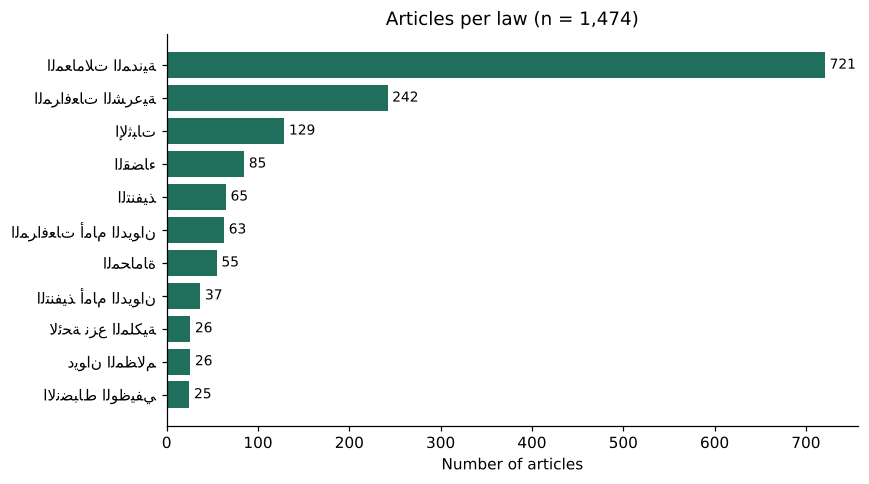

In [7]:
fig = eda.articles_per_law(df); fig.savefig(config.FIG_DIR / "articles_per_law.png", dpi=200); plt.show()

> 💡 **Insight.** Strong imbalance: Civil Transactions is about half the corpus and three laws have fewer than 30 articles. For classification we therefore use `class_weight="balanced"` and rank by **macro-F1**; plain accuracy would reward predicting the big class.

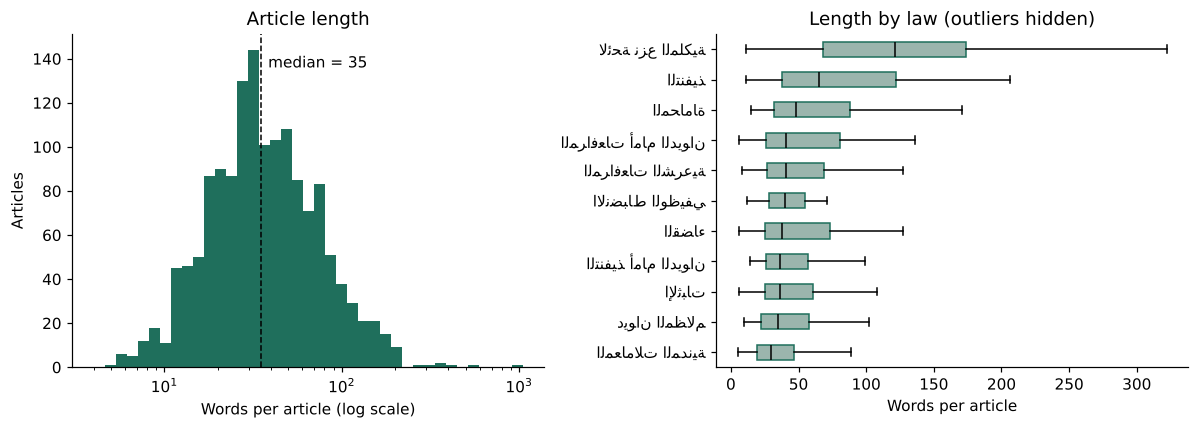

In [8]:
fig = eda.length_distribution(df); fig.savefig(config.FIG_DIR / "length.png", dpi=200); plt.show()

> 💡 **Insight.** Heavy-tailed lengths: median ≈ 35 words, a few articles exceed 1,000. BM25 normalizes for length, and bge-m3's 512-token limit still covers more than 99% of articles, so truncation is not a concern.

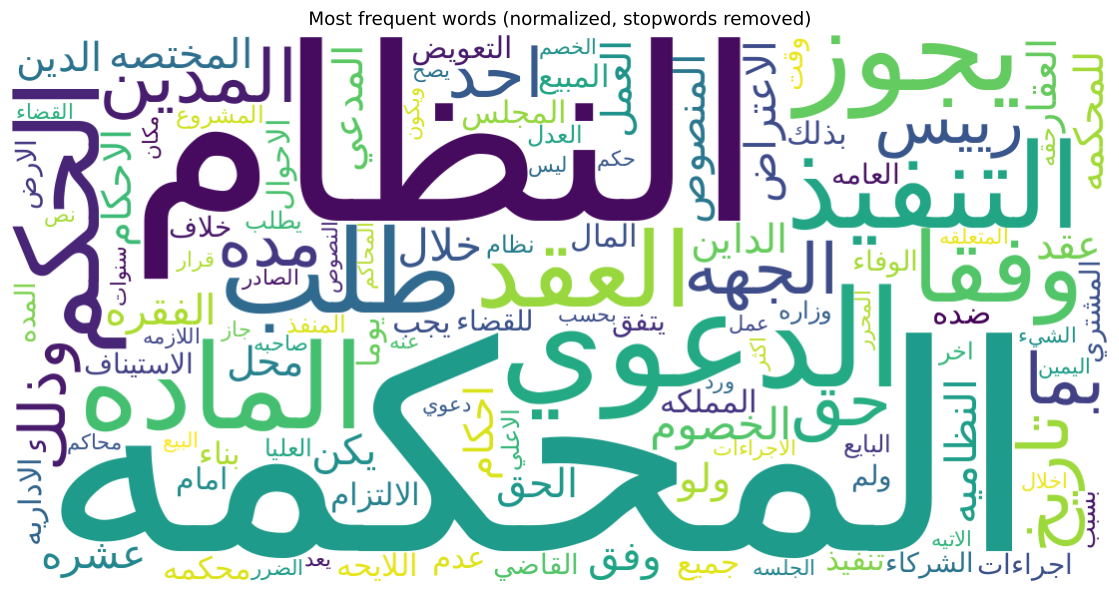

In [9]:
fig = eda.wordcloud(df); fig.savefig(config.FIG_DIR / "wordcloud.png", dpi=200); plt.show()

> 💡 **Insight.** The dominant words are court-procedure terms (المحكمة، الدعوى، الحكم، التنفيذ). Because most articles share them, single frequent words cannot separate articles; the rarer, specific terms do.

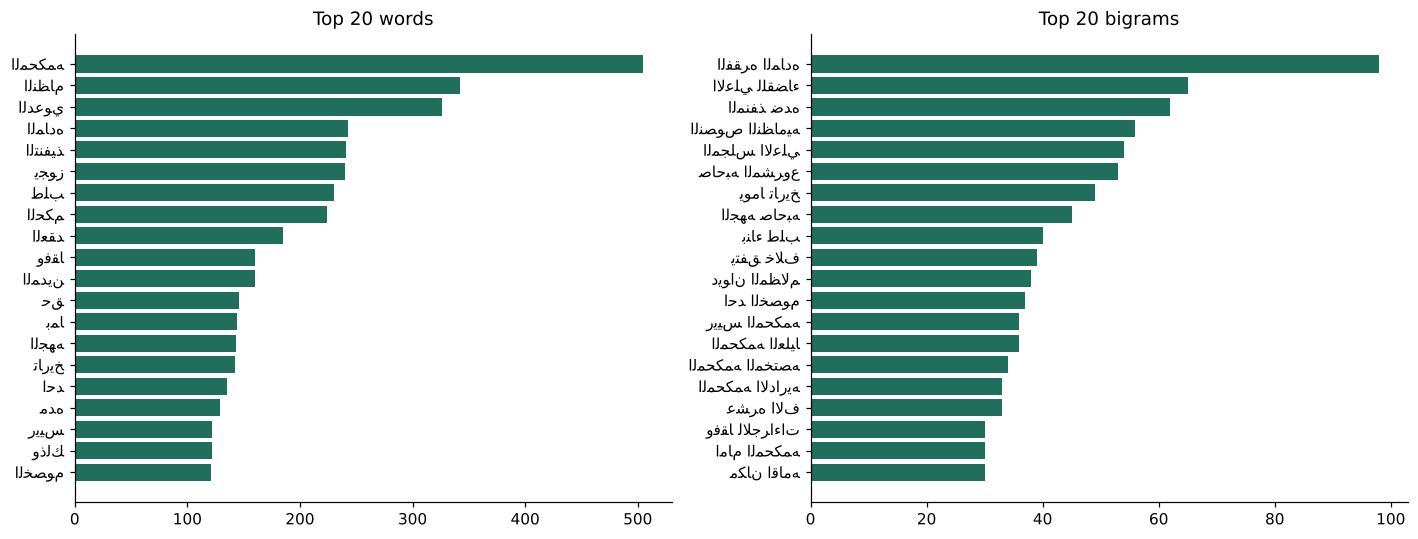

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, n, title in [(axes[0], 1, "Top 20 words"), (axes[1], 2, "Top 20 bigrams")]:
    pairs = eda.top_ngrams(df, n, 20)[::-1]
    ax.barh([eda.ar(w) for w, _ in pairs], [c for _, c in pairs], color=eda.ACCENT); ax.set_title(title)
fig.tight_layout(); fig.savefig(config.FIG_DIR / "ngrams.png", dpi=200); plt.show()

> 💡 **Insight.** Bigrams are fixed legal collocations (المنصوص عليها، المجلس الأعلى للقضاء، المنفذ ضده). Users rarely write these, which motivates (1) word bigrams in TF-IDF and (2) semantic embeddings to bridge everyday and formal wording.

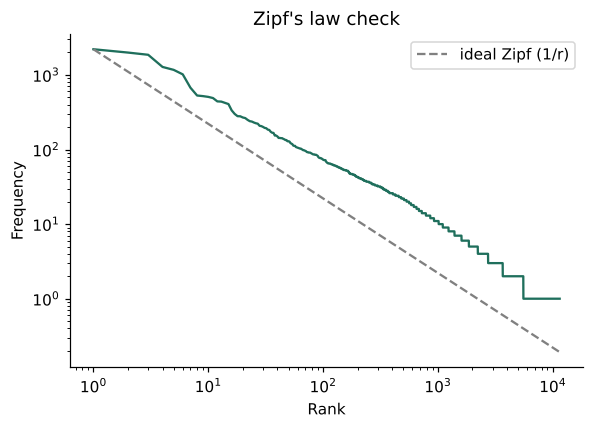

In [11]:
fig = eda.zipf(df); fig.savefig(config.FIG_DIR / "zipf.png", dpi=200); plt.show()

> 💡 **Insight.** Word frequencies follow Zipf's law with a long tail of rare words. Those rare terms are the most informative for retrieval, which is exactly what IDF weighting rewards.

## 5. Text representations
TF-IDF · BM25 · FastText (trained here) · bge-m3 · cross-encoder reranker

In [12]:
from src.retriever import build_retrievers
chunks, R = build_retrievers(chunks, use_dense=RUN_DENSE, use_rerank=RUN_RERANK)
print("retrievers:", list(R))
X = R["tfidf"].X
print(f"TF-IDF matrix: {X.shape[0]:,} articles × {X.shape[1]:,} features, sparsity {1 - X.nnz / np.prod(X.shape):.2%}")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 41292.50it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9722.67it/s]

retrievers: ['tfidf', 'bm25', 'fasttext', 'dense', 'hybrid', 'hybrid+rerank']
TF-IDF matrix: 1,474 articles × 40,739 features, sparsity 99.83%


In [13]:
# What did FastText learn? nearest neighbours of a few legal terms (in the normalized + stemmed space)
wv = R["fasttext"].model.wv
for w in ["دعوي", "تعويض", "استيناف", "قرار"]:
    print(f"{w:>8} →", ", ".join(f"{n}" for n, _ in wv.most_similar(w, topn=6)))

    دعوي → بدعوي, دعوه, دعي, دعاوي, دعواه, اقوي
   تعويض → لتعويض, تعويضا, تعويضه, بتعويض, تعويضات, بتعويضه
 استيناف → استيناس, استينافها, استيذان, استثناييه, استثناء, تدقيق
    قرار → لقرار, قرارا, بقرار, قرارها, قراراته, اقرار


> 💡 **Insight.** With only ~50k training tokens, FastText's neighbours are surface-form relatives (تعويض → تعويضات، بتعويض) or words that merely share letters (استيناف → استيناس). It handles morphology but has not learned legal *meaning*, so we expect it to be the weakest semantic model.

## 6. Experiment A — Law classification ("law router")
Predict the law of an article from its body · nested stratified 5-fold CV (inner 3-fold tuning) · macro-F1

In [14]:
labels = sorted(df.law_key.unique())
y = df.law_key.values
models = [("TF-IDF + Logistic Regression", classify.tfidf_logreg, df.text),
          ("TF-IDF + Complement Naive Bayes", classify.tfidf_nb, df.text),
          ("FastText (own) + Logistic Regression", classify.fasttext_logreg, df.text)]   # ~4 min on CPU
if RUN_DENSE:
    models.append(("bge-m3 (frozen) + Logistic Regression", classify.bge_logreg, classify.encode_bge(df.text)))

results = [classify.nested_cv(name, make, X, y, labels) for name, make, X in models]
clf_table = (pd.DataFrame([{k: r[k] for k in ["model", "accuracy", "macro_F1", "weighted_F1", "params (most chosen)"]}
                           for r in results]).set_index("model"))
display(clf_table)

  TF-IDF + Logistic Regression fold 1: macro-F1 0.826  {'logisticregression__C': 1}


  TF-IDF + Logistic Regression fold 2: macro-F1 0.835  {'logisticregression__C': 10}


  TF-IDF + Logistic Regression fold 3: macro-F1 0.766  {'logisticregression__C': 1}


  TF-IDF + Logistic Regression fold 4: macro-F1 0.821  {'logisticregression__C': 100}


  TF-IDF + Logistic Regression fold 5: macro-F1 0.778  {'logisticregression__C': 100}


  TF-IDF + Complement Naive Bayes fold 1: macro-F1 0.772  {'complementnb__alpha': 0.1}


... (11 outputs left out)

  bge-m3 (frozen) + Logistic Regression fold 3: macro-F1 0.654  {'C': 100}


  bge-m3 (frozen) + Logistic Regression fold 4: macro-F1 0.814  {'C': 100}


  bge-m3 (frozen) + Logistic Regression fold 5: macro-F1 0.760  {'C': 100}


,accuracy,macro_F1,weighted_F1,params (most chosen)
model,,,,
TF-IDF + Logistic Regression,0.882 ± 0.013,0.805 ± 0.031,0.880 ± 0.014,{'logisticregression__C': 1}
TF-IDF + Complement Naive Bayes,0.866 ± 0.018,0.756 ± 0.038,0.860 ± 0.020,{'complementnb__alpha': 0.1}
FastText (own) + Logistic Regression,0.754 ± 0.026,0.630 ± 0.043,0.760 ± 0.021,{'logisticregression__C': 10}
bge-m3 (frozen) + Logistic Regression,0.841 ± 0.023,0.756 ± 0.063,0.841 ± 0.023,{'C': 100}


> 💡 **Insight.** **TF-IDF + Logistic Regression is the best model** (macro-F1 ≈ 0.81 ± 0.03, accuracy ≈ 0.88). Each law has its own technical vocabulary, and a linear model on sparse n-grams uses exactly those terms. Complement NB and frozen bge-m3 tie second (≈ 0.76); FastText is last (≈ 0.63) because its averaged vectors blur the few discriminative words. Hyperparameters (C, alpha) were tuned in the inner 3-fold loop only, so the outer score is unbiased.

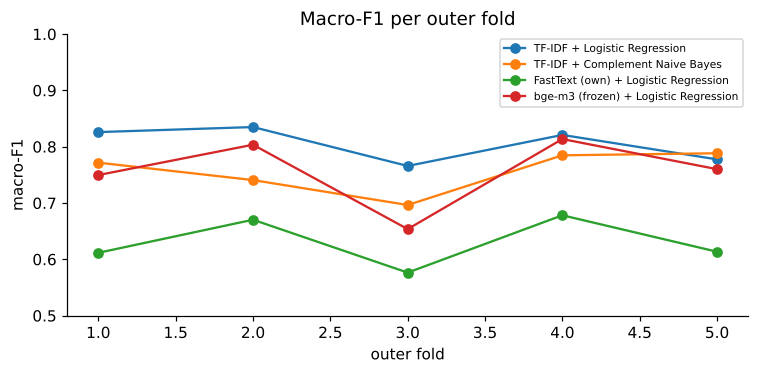

In [15]:
# Fold-by-fold macro-F1: how stable is each model?
folds = pd.DataFrame({r["model"]: r["folds"]["macro_F1"].values for r in results}, index=range(1, 6))
ax = folds.plot(marker="o", figsize=(7, 3.5)); ax.set(xlabel="outer fold", ylabel="macro-F1", ylim=(0.5, 1),
                                                    title="Macro-F1 per outer fold")
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(config.FIG_DIR / "cv_folds.png", dpi=200); plt.show()

> 💡 **Insight.** Fold-to-fold spread shows how much one split can mislead: a single 80/20 split we tried first gave 0.90, while the 5 folds range 0.77–0.84. bge-m3 is the least stable (± 0.06). Every article is tested once by a model that never saw it, and tuning never touches the test fold, so the score is not inflated by overfitting to the test set.

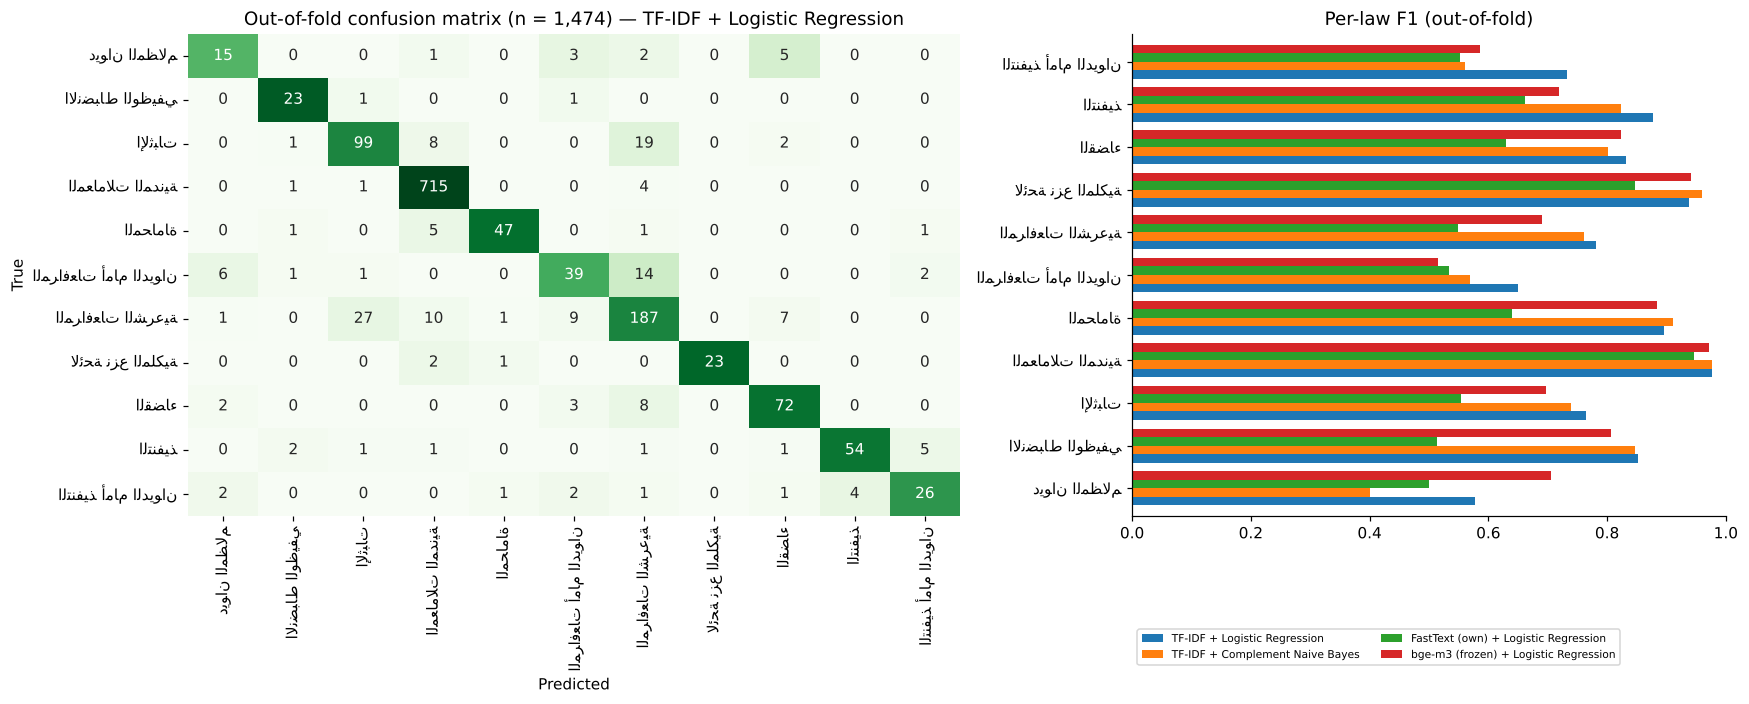

In [16]:
best = max(results, key=lambda r: r["macro_F1_mean"])
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
names = [eda.ar(eda.SHORT[l]) for l in labels]
cm = best["confusion"] / best["confusion"].sum(1, keepdims=True)
sns.heatmap(cm, annot=best["confusion"], fmt="d", cmap="Greens", xticklabels=names, yticklabels=names,
            cbar=False, ax=axes[0])
axes[0].set(title=f"Out-of-fold confusion matrix (n = {len(df):,}) — {best['model']}", xlabel="Predicted", ylabel="True")
f1 = pd.DataFrame({r["model"]: {l: r["report"][l]["f1-score"] for l in labels} for r in results})
f1.index = names
f1.plot.barh(ax=axes[1], width=0.8)
axes[1].set(title="Per-law F1 (out-of-fold)", xlim=(0, 1))
axes[1].legend(fontsize=7, loc="lower left", bbox_to_anchor=(0, -0.32), ncol=2)
fig.tight_layout(); fig.savefig(config.FIG_DIR / "classification.png", dpi=200, bbox_inches="tight"); plt.show()

> 💡 **Insight.** Civil Transactions is almost perfect (F1 ≈ 0.98); the weakest classes are the smallest Board laws (ديوان المظالم ≈ 0.58). Most errors sit between procedure laws that regulate the same steps.

In [17]:
# Error analysis: the most frequent confusions of the best model
err = df.assign(pred=best["pred"]).query("law_key != pred")
print(f"{len(err)} errors out of {len(df):,} articles\n")
pairs = err.groupby(["law_key", "pred"]).size().sort_values(ascending=False).head(6)
display(pairs.rename("count").to_frame())
display(err[["id", "law_key", "pred", "text"]].head(6))

174 errors out of 1,474 articles



count
law_key         pred                  
murafaat_sharia ithbat              27
ithbat          murafaat_sharia     19
murafaat_diwan  murafaat_sharia     14
murafaat_sharia muamalat            10
                murafaat_diwan       9
ithbat          muamalat             8

,id,law_key,pred,text
6,diwan_al_mazalim#007,diwan_al_mazalim,qada,يكون للمجلس أمانة عامة، ويختار المجلس الأمين العام من بين القضاة.
10,diwan_al_mazalim#011,diwan_al_mazalim,murafaat_diwan,تختص المحكمة الإدارية العليا بالنظر في الاعتراضات على الأحكام التي تصدرها محاكم\nالاستئناف الإدارية ، إذا كان محل ال...
11,diwan_al_mazalim#012,diwan_al_mazalim,murafaat_diwan,تتولى محاكم الاستئناف الإدارية النظر في الأحكام القابلة للاستئناف الصادرة من المحاكم الإدارية، وتحكم بعد سماع أقوال ...
12,diwan_al_mazalim#013,diwan_al_mazalim,murafaat_sharia,تختص المحاكم الإدارية بالفصل في الآتي:\nأ ـ الدعاوى المتعلقة بالحقوق المقررة في نظم الخدمة المدنية والعسكرية والتقاع...
15,diwan_al_mazalim#016,diwan_al_mazalim,qada,درجات قضاة الديوان هي الدرجات المنصوص عليها في نظام القضاء، ويعاملون من حيث الرواتب والبدلات والمكافآت والمزايا معام...
18,diwan_al_mazalim#019,diwan_al_mazalim,muamalat,يتولى نواب الرئيس الأعمال التي يكلفهم بها الرئيس، ويحل محله في حال غيابه أو خلو منصبه أقدم نوابه، وذلك دون إخلال بما...


> 💡 **Insight.** 174 / 1,474 errors, and they are legally sensible: Sharia Procedure ↔ Evidence (27 + 19) and Board Procedure → Sharia Procedure (14). These laws describe the same steps (الدعوى، الإقرار، الشهادة), and the Board procedure law explicitly refers back to the Sharia Procedure Law.

## 7. Experiment B — Retrieval for RAG (main task)
Rank 1,474 articles per question · 5-fold CV over questions (hybrid weight tuned on training folds) · R@k · MRR · nDCG

In [18]:
from eval.evaluate import load_questions, crossval, summarize, METRICS
qs = load_questions(chunk_ids={c.id for c in chunks})
print(f"{len(qs)} questions | sources: {qs.source.value_counts().to_dict()} | per fold: {qs.fold.value_counts().sort_index().tolist()}")
ENOUGH = len(qs) >= 20
if not ENOUGH:
    display(Markdown("⚠️ **Not enough evaluation questions yet.** Add them with `streamlit run app/annotate.py`, then re-run from here."))
else:
    display(qs.groupby("source").sample(2, random_state=0)[["qid", "question", "gold_ids", "source"]])
    print("Questions per law:", qs.gold.map(lambda g: g[0].split("#")[0]).value_counts().to_dict())

160 questions | sources: {'ai': 160} | per fold: [32, 32, 32, 32, 32]


,qid,question,gold_ids,source
110,ai-111,موظف ارتكب مخالفة وبعدين انتقل لجهة ثانية، مين يحقق معه؟,indibat#012,ai
112,ai-113,لمن ترسل الجهة الحكومية نسخة من قرار الجزاء على الموظف؟,indibat#016,ai


Questions per law: {'muamalat': 26, 'murafaat_diwan': 24, 'murafaat_sharia': 20, 'ithbat': 14, 'diwan_al_mazalim': 12, 'tanfeedh_diwan': 12, 'qada': 12, 'tanfeedh': 12, 'indibat': 10, 'muhamah': 10, 'nazaa_reg': 8}


> 💡 **Insight.** 160 evaluation questions covering all 11 laws, each labeled with its governing article. They were drafted with an AI assistant from their gold articles in formal and colloquial Arabic, then checked (see the acknowledgement). They are used **only to measure** retrieval; the corpus itself is 100% real legislation.

In [19]:
if ENOUGH:
    detail, tuning = crossval(R, chunks, qs)
    overall = summarize(detail, qs)
    display(overall)

  scoring tfidf …
  scoring bm25 …


  scoring fasttext …
  scoring dense …


  reranking fold 1 (w=1.0) …


  reranking fold 2 (w=1.0) …


  reranking fold 3 (w=1.0) …


  reranking fold 4 (w=1.0) …


  reranking fold 5 (w=1.0) …


,set,n,R@1,R@3,R@5,R@10,MRR@10,nDCG@10,MRR 95% CI
retriever,,,,,,,,,
tfidf,all,160,0.319,0.488,0.588,0.669,0.427,0.485,"[0.37, 0.49]"
bm25,all,160,0.369,0.550,0.606,0.731,0.482,0.542,"[0.42, 0.55]"
fasttext,all,160,0.206,0.412,0.481,0.612,0.328,0.396,"[0.27, 0.39]"
dense,all,160,0.650,0.850,0.912,0.969,0.765,0.815,"[0.71, 0.82]"
hybrid,all,160,0.650,0.850,0.912,0.969,0.765,0.815,"[0.71, 0.82]"
hybrid+rerank,all,160,0.800,0.931,0.962,0.975,0.869,0.895,"[0.83, 0.91]"


> 💡 **Insight.** **Semantic retrieval dominates.** bge-m3 finds a correct article in the top 5 for 91% of questions vs 61% for BM25 and 59% for TF-IDF: questions use everyday wording, the law uses formal drafting, and only embeddings bridge that gap. The cross-encoder reranker is the best system: **R@1 0.65 → 0.80, MRR 0.77 → 0.87, R@5 0.96**. FastText is weakest (R@5 0.48), consistent with Experiment A.

,fold,chosen w,train MRR@10,held-out MRR@10
0,1,1.0,0.783,0.693
1,2,1.0,0.756,0.800
2,3,1.0,0.774,0.730
3,4,1.0,0.735,0.885
4,5,1.0,0.777,0.716


MRR@10 of the hybrid for each w (all questions): {0.0: np.float64(0.482), 0.2: np.float64(0.603), 0.4: np.float64(0.655), 0.5: np.float64(0.678), 0.6: np.float64(0.685), 0.8: np.float64(0.734), 1.0: np.float64(0.765)}


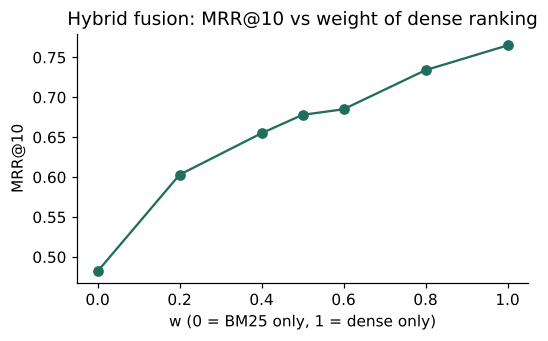

In [20]:
if ENOUGH and tuning is not None:
    display(tuning)
    print("MRR@10 of the hybrid for each w (all questions):", tuning.attrs["mrr_by_w"])
    ax = pd.Series(tuning.attrs["mrr_by_w"]).plot(marker="o", figsize=(5, 3.2), color=eda.ACCENT)
    ax.set(title="Hybrid fusion: MRR@10 vs weight of dense ranking", xlabel="w (0 = BM25 only, 1 = dense only)", ylabel="MRR@10")
    plt.tight_layout(); plt.savefig(config.FIG_DIR / "hybrid_w.png", dpi=200); plt.show()

> 💡 **Insight.** Fusion did not help: hybrid MRR rises steadily with the dense weight (0.48 at w = 0 → 0.77 at w = 1), and every training fold chose w = 1.0, i.e. dense only. Held-out MRR stays close to training MRR, so the tuned weight is not overfitted. When one retriever is this much stronger, BM25 adds noise rather than complementary signal.

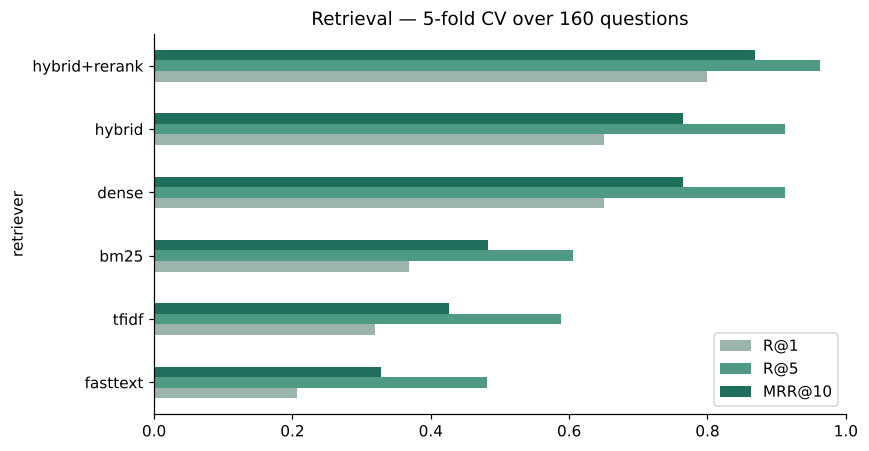

In [21]:
if ENOUGH:
    order = overall["MRR@10"].sort_values().index
    ax = overall.loc[order, ["R@1", "R@5", "MRR@10"]].plot.barh(figsize=(8, 4.2), color=["#9bb5ad", "#4f9a85", "#1f6f5c"])
    ax.set(title=f"Retrieval — 5-fold CV over {len(qs)} questions", xlim=(0, 1))
    plt.tight_layout(); plt.savefig(config.FIG_DIR / "retrieval.png", dpi=200); plt.show()
    if qs.source.nunique() > 1:
        display(summarize(detail, qs, "source")[["n", "R@1", "R@5", "MRR@10"]])

> 💡 **Insight.** The reranked system is best on every metric. The 95% bootstrap intervals for MRR do not overlap (BM25 [0.42, 0.55], bge-m3 [0.71, 0.82], reranked [0.83, 0.91]), so the gaps are not due to chance.

In [22]:
# Error analysis — what does the best model miss, and do models fail on the same questions?
if ENOUGH:
    best_r = overall["MRR@10"].idxmax()
    cid = {c.id: c.citation for c in chunks}
    d = detail[best_r].join(qs[["question", "gold_ids", "source"]])
    misses = d[d["R@5"] == 0]
    print(f"Best: {best_r} — {len(misses)} of {len(d)} questions have no correct article in the top 5\n")
    for r in misses.head(8).itertuples():
        print(f"Q: {r.question}\n   gold: {[cid[g] for g in r.gold_ids.split(';')]}\n   top1: {cid.get(r.top1)}\n")
    hit = pd.DataFrame({n: dd["R@5"] for n, dd in detail.items()})
    print("Solved (R@5) by every model:", int((hit.sum(1) == hit.shape[1]).sum()),
          "| by none:", int((hit.sum(1) == 0).sum()))
    if "dense" in hit:
        lex_only = hit[(hit[["tfidf", "bm25"]].max(1) == 1) & (hit["dense"] == 0)].index
        sem_only = hit[(hit[["tfidf", "bm25"]].max(1) == 0) & (hit["dense"] == 1)].index
        print(f"Found only by a lexical model: {len(lex_only)} | only by dense: {len(sem_only)}  → complementarity")

Best: hybrid+rerank — 6 of 160 questions have no correct article in the top 5

Q: متى تعتبر الخصومة حضورية حتى لو غاب أحد الطرفين بعدين؟
   gold: ['نظام المرافعات أمام ديوان المظالم — المادة السادسة عشرة']
   top1: نظام المرافعات الشرعية — المادة الثامنة والخمسون

Q: هل يقدر شخص ما هو طرف في القضية ياخذ صورة من الحكم؟
   gold: ['نظام المرافعات أمام ديوان المظالم — المادة الثامنة والعشرون']
   top1: نظام المرافعات أمام ديوان المظالم — المادة الرابعة عشرة

Q: هل أقدر أطعن في حكم التأديب الصادر ضد قاضي؟
   gold: ['نظام القضاء — المادة الخامسة والستون']
   top1: نظام المحاماة — المادة الحادية والثلاثون

Q: كيف يؤدي الشخص الأخرس الشهادة أو اليمين في المحكمة؟
   gold: ['نظام الإثبات — المادة الثانية عشرة']
   top1: نظام الإثبات — المادة الحادية عشرة

Q: المدين باع بيته بعد ما بلغوه بالتنفيذ عشان يهرب من الدين، هل أقدر أبطل البيع؟
   gold: ['نظام التنفيذ — المادة الرابعة والعشرون']
   top1: نظام المعاملات المدنية — المادة التاسعة والخمسون بعد الثلاثمائة

Q: الجهة تبي تفصل موظف بعد التحقيق، وش

> 💡 **Insight.** Only 6 of 160 questions miss the top 5. The misses share three patterns: **parallel laws** (General vs Board enforcement/procedure laws use nearly the same sentences), **neighbouring articles** (art. 11 vs 12 of the Evidence Law), and **implicit concepts** (the question never names the legal term the article uses).

## 8. The RAG system — end-to-end demo
Best retriever → top-5 articles → cite-or-refuse LLM prompt (verbatim articles if no API key)

In [23]:
from src.pipeline import LegalRAG
rag = LegalRAG(chunks=chunks, retrievers=R)
res = rag.ask("رفعت دعوى على جهة حكومية، هل لازم أتظلم عندهم أول؟ وكم المدة؟")
print(f"retriever: {res['retriever']} | generation: {res['mode']}\n")
print(res["answer"][:800])
print("\nSources:")
for s in res["sources"]:
    print(f"  [{s['rank']}] {s['citation']}")

retriever: hybrid+rerank | generation: extractive

أقرب النصوص النظامية ذات الصلة بسؤالك:

**نظام المرافعات أمام ديوان المظالم — المادة الثامنة** [1]
يجب في الدعاوى المنصوص عليها في الفقرة (أ) من المادة (الثالثة عشرة) من نظام ديوان المظالم، أن يسبق رفعها إلى المحكمة الإدارية التظلم إلى وزارة الخدمة المدنية أو الجهة العسكرية التابع لها الموظف خلال عشر سنوات من تاريخ نشوء الحق المدعى به، ما لم يقر المدعى عليه بالحق أو يكن ثمة عذر شرعي حال دون رفع الدعوى يثبت لدى المحكمة. وعلى وزارة الخدمة المدنية أو الجهة العسكرية التابع لها الموظف أن تبت في التظلم خلال ستين يوماً من تاريخ تقديمه.
إذا صدر قرار وزارة الخدمة المدنية أو الجهة العسكرية التابع لها الموظف برفض التظلم، أو مضت المدة المحددة في الفقرة السابقة دون البت فيه، جاز رفع الدعوى إلى المحكمة الإدارية خلال ستين يوماً من تاريخ العلم بالقرار الصادر بالرفض أو انقضاء الستين يوماً المذكورة دون البت

Sources:
  [1] نظام المرافعات أمام ديوان المظالم — المادة الثامنة
  [2] نظام المرافعات الشرعية — المادة الخامسة والثمانون بعد المائة
  [3] نظام الت

> 💡 **Insight.** The system returns the governing article with its citation. Without an API key it shows the retrieved articles verbatim; with one, the LLM must cite every claim as [n] or say it cannot find the answer, so it never invents a law.

## 9. Conclusions, limitations and future work
**Conclusions**
- An original corpus of **1,474 articles from 11 Saudi laws**, collected from the official source with full citations.
- Arabic preprocessing cuts the vocabulary by 42%, which directly helps lexical matching.
- **Experiment A (which law?):** TF-IDF + Logistic Regression is best, macro-F1 **0.81 ± 0.03** (nested 5-fold CV).
- **Experiment B (which article?):** bge-m3 beats every lexical model (R@5 0.91 vs 0.61); with the reranker: **R@1 0.80, R@5 0.96, MRR 0.87**.
- The task decides the representation: sparse n-grams win at *law style*, dense semantics win at *meaning across registers*.

**Limitations**
- The 160 questions were drafted by an AI assistant from their gold articles, not asked by real litigants.
- One law (Civil Transactions) is 49% of the corpus; the main expropriation law could not be retrieved from the source.
- The faithfulness of generated answers is not measured, only retrieval.

**Future work**
- Collect real questions from the public; add Board of Grievances judgments.
- Fine-tune bge-m3 on (question, article) pairs; route each question to its law first; link cross-references between laws.

### Launch the interactive demo (public link)
Set `LAUNCH_DEMO = True` → public link to the Gradio interface

In [24]:
LAUNCH_DEMO = False          # ← set True before the presentation: prints a public https://….gradio.live link
if LAUNCH_DEMO:
    from app.gradio_app import launch
    launch(share=True)